# REGRESSION ANALYSIS OF EARNINGS
- Author:- Arnold Atchoe.
- Date:- 2026-11
- Dataset:- 
- Target Feature:- Net Income as percentage of revenue(Net Income Percentage)

This model fits a line to generate regression functions for each company that predicts net income as a percentage of revenue given, cost of revenue as percentage of revenue, operating expenses as percentage of revenue and interest expense as a percentage of revenue. Regression function generated is assess using the metrics:
- RMSE:- Root mean squared error, the typical size of a miss, in the target's units.
- R-squared:- The fraction of the variation in the target the model explains (roughly 0 to 1; higher is more).
- Residual plot:- Actual minus predicted. If a straight line fits well, residuals scatter randomly around zero with no pattern. A curve or a funnel says the line is the wrong shape - itself a useful finding.

## Section 1. Project Setup and Imports

In [49]:
# Section 1a: Declare imports
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import RANSACRegressor, QuantileRegressor
from sklearn.linear_model import HuberRegressor, Lasso
from sklearn.pipeline import Pipeline
from sklearn.linear_model import TheilSenRegressor


## Section 2: Load and Prepare Regression Data

  Ticker  Cost of Revenue %  Operating Expense %  Interest Expense %  \
0    WMT          76.268193            17.239952            0.432992   
1    WMT          75.700004            17.894776            0.561306   
2    WMT          75.700172            18.455589            0.513215   
3    WMT          75.064012            18.549771            0.459301   
4    WMT          74.903747            18.217601            0.491578   

   Net Income %  
0      3.975656  
1      3.812786  
2      3.475201  
3      4.075635  
4      5.204538  


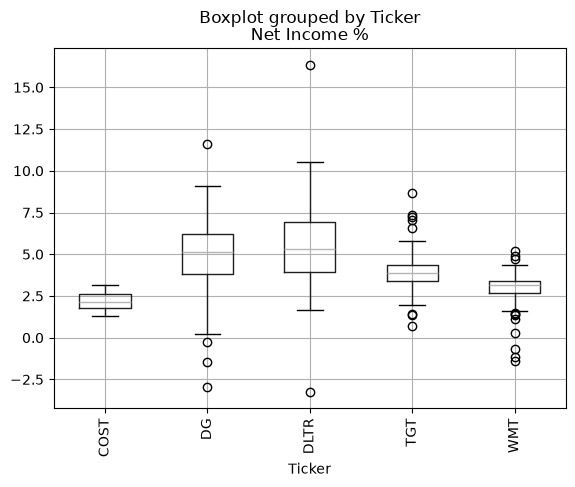

Features: 0      76.268193
1      75.700004
2      75.700172
3      75.064012
4      74.903747
         ...    
355    88.163571
356    87.686695
357    87.315708
358    87.094340
359    87.263249
Name: Cost of Revenue %, Length: 360, dtype: float64, 0      17.239952
1      17.894776
2      18.455589
3      18.549771
4      18.217601
         ...    
355     8.372751
356     8.790332
357     8.867335
358     9.027810
359     8.765918
Name: Operating Expense %, Length: 360, dtype: float64, 0      0.432992
1      0.561306
2      0.513215
3      0.459301
4      0.491578
         ...   
355    0.066583
356    0.070941
357    0.061483
358    0.053392
359    0.047011
Name: Interest Expense %, Length: 360, dtype: float64
Target: 0      3.975656
1      3.812786
2      3.475201
3      4.075635
4      5.204538
         ...   
355    2.591169
356    2.736290
357    2.953687
358    3.029389
359    3.131954
Name: Net Income %, Length: 360, dtype: float64


In [50]:
## Section 2a: Load data from csv file
parent_dir = Path.cwd().parent
data_dir = parent_dir / "data"
processed_data_dir = data_dir / "processed"
ml_data = pd.read_csv(processed_data_dir / "ml_data.csv")
print(ml_data.head())

# View boxplot of net income percentage data per ticker
ml_data.boxplot(column="Net Income %", by="Ticker", rot=90)
plt.show()

## Section 2b: Specify features and target variable
feature_1 = ml_data["Cost of Revenue %"]
feature_2 = ml_data["Operating Expense %"]
feature_3 = ml_data["Interest Expense %"]
target = ml_data["Net Income %"]

print(f"Features: {feature_1}, {feature_2}, {feature_3}")
print(f"Target: {target}")

x=pd.concat([feature_1, feature_2, feature_3], axis=1)
y = target

## Section 3: Split into Train and Test datasets.

## Section 4: Fit a Straight Line


Ticker     Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  Test R²
   WMT    RANSAC    0.787400   1.243245   0.458425  0.666454  0.340384 0.369372
   WMT Theil-Sen    0.779400   1.226658   0.457765  0.679896  0.353719 0.386087
   WMT     Huber    0.782430   1.255732   0.458843  0.694724  0.348685 0.356641
   WMT  Quantile    0.784671   1.234635   0.455250  0.674218  0.344949 0.378077


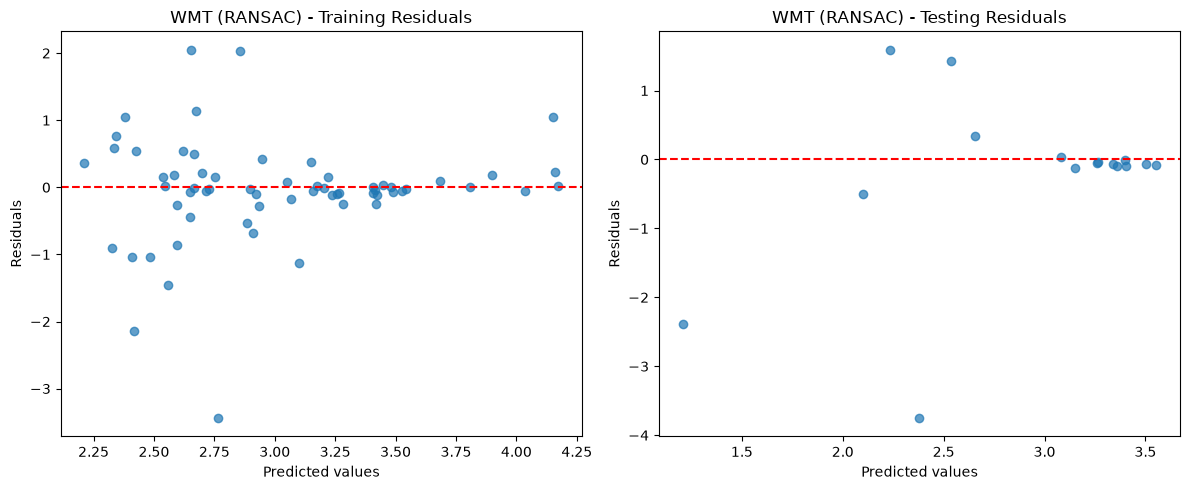

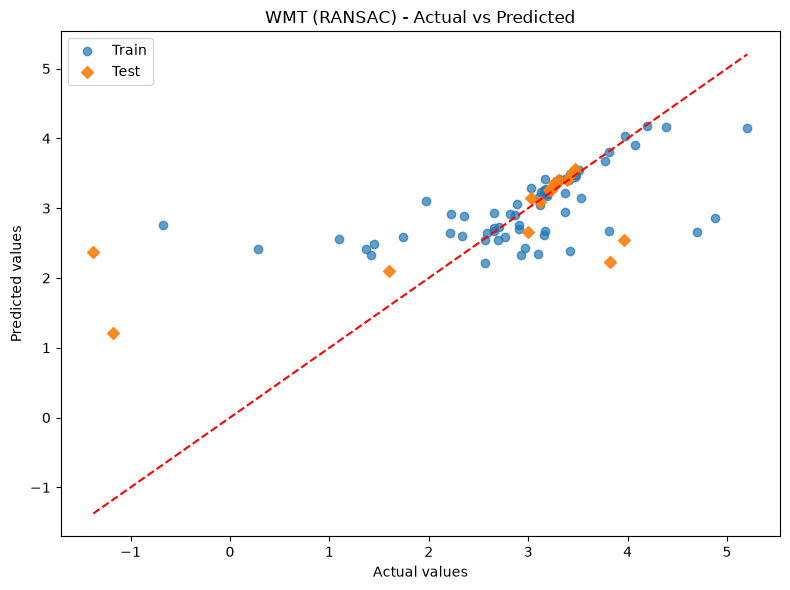


Best model for WMT: RANSAC
Coefficients: [-0.57245285 -0.60736311 -1.21274164]
Intercept: 58.6933
Regression equation: y = 58.6933 + (-0.5725 * Cost of Revenue %) + (-0.6074 * Operating Expense %) + (-1.2127 * Interest Expense %)
------------------------------------------------------------
Ticker     Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  Test R²
   TGT    RANSAC    2.817184   0.747291   0.767169  0.442013 -0.238024 0.791848
   TGT Theil-Sen    2.791597   0.717777   0.748958  0.429150 -0.215638 0.807965
   TGT     Huber    2.778406   0.690192   0.757100  0.434074 -0.204176 0.822442
   TGT  Quantile    2.785807   0.732657   0.748333  0.436048 -0.210600 0.799920


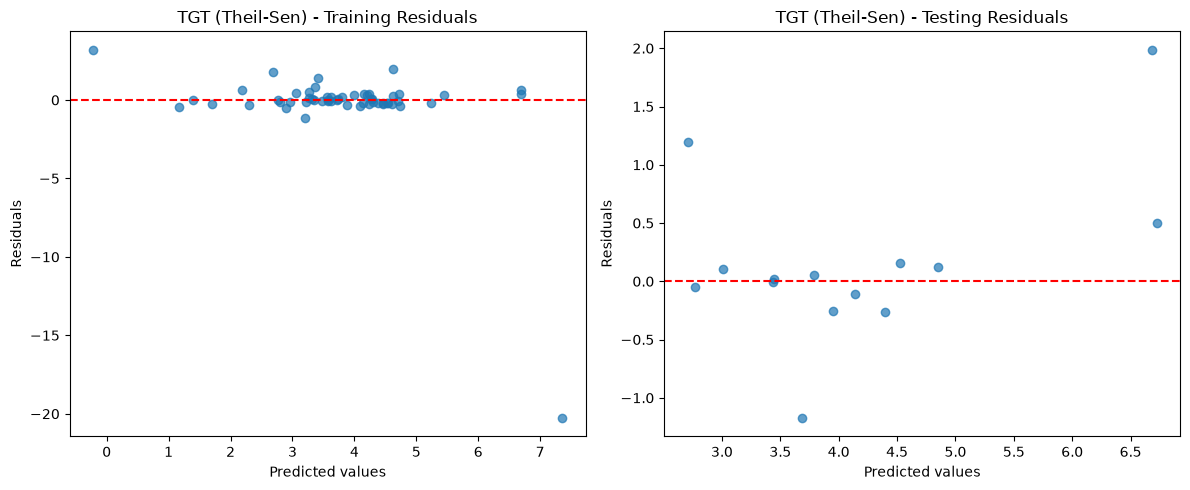

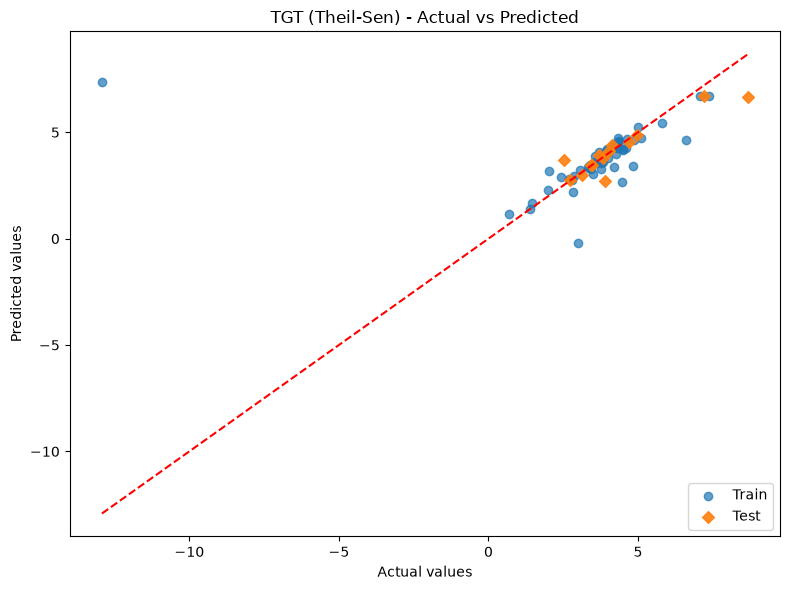


Best model for TGT: Theil-Sen
Coefficients: [-0.64533063 -0.6409162  -1.35968038]
Intercept: 65.3945
Regression equation: y = 65.3945 + (-0.6453 * Cost of Revenue %) + (-0.6409 * Operating Expense %) + (-1.3597 * Interest Expense %)
------------------------------------------------------------
Ticker     Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²   Test R²
  DLTR    RANSAC   12.568879   2.647013   3.211981  1.124769 -0.122832  0.044095
  DLTR Theil-Sen   12.580165   2.962305   3.253039  1.493121 -0.124850 -0.197186
  DLTR     Huber   12.523185   2.532554   3.195990  1.120479 -0.114683  0.124976
  DLTR  Quantile   12.522213   2.622705   3.182918  1.130822 -0.114510  0.061572


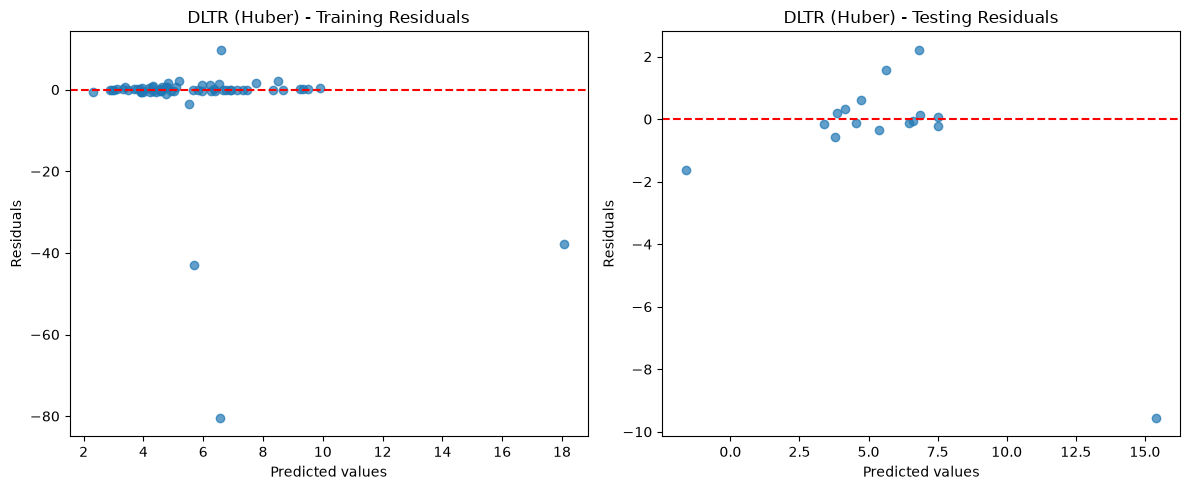

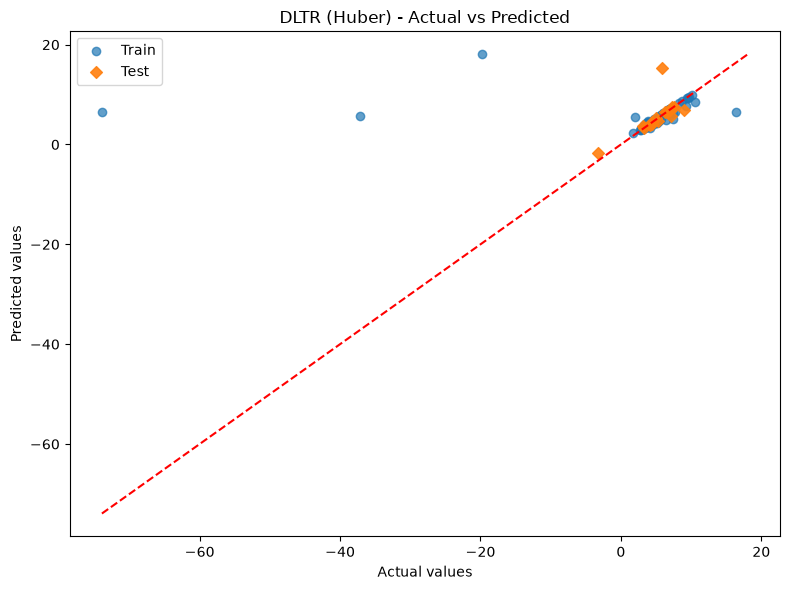


Best model for DLTR: Huber
Coefficients: [-0.55567467 -0.56288119 -0.54578264]
Intercept: 56.6305
Regression equation: y = 56.6305 + (-0.5557 * Cost of Revenue %) + (-0.5629 * Operating Expense %) + (-0.5458 * Interest Expense %)
------------------------------------------------------------
Ticker     Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  Test R²
    DG    RANSAC    0.658688   1.639189   0.524185  1.140711  0.910213 0.618743
    DG Theil-Sen    0.584215   1.459043   0.505921  0.951847  0.929369 0.697938
    DG     Huber    0.566284   1.385566   0.479226  0.826305  0.933638 0.727595
    DG  Quantile    0.612003   1.471871   0.460227  0.853276  0.922490 0.692603


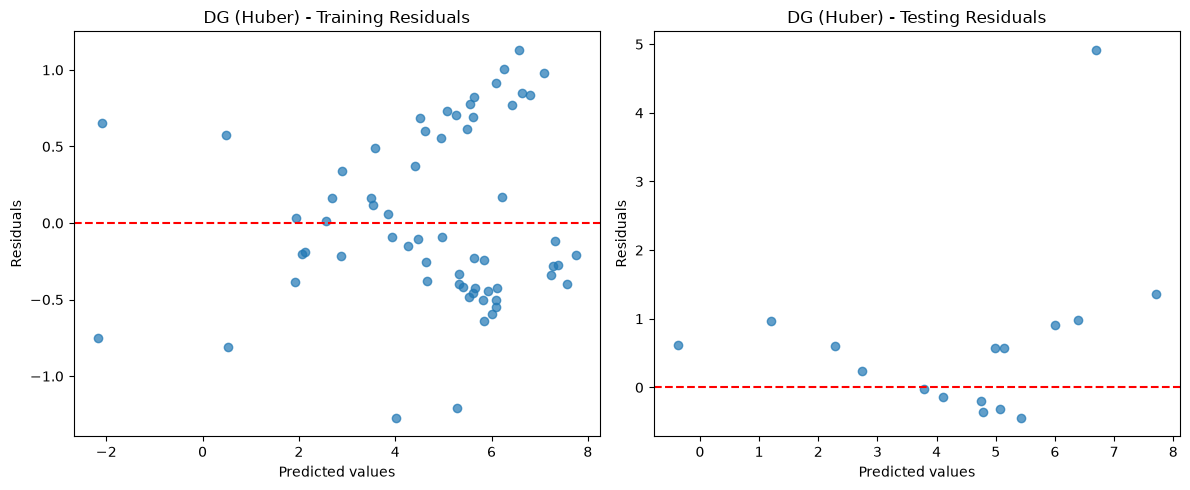

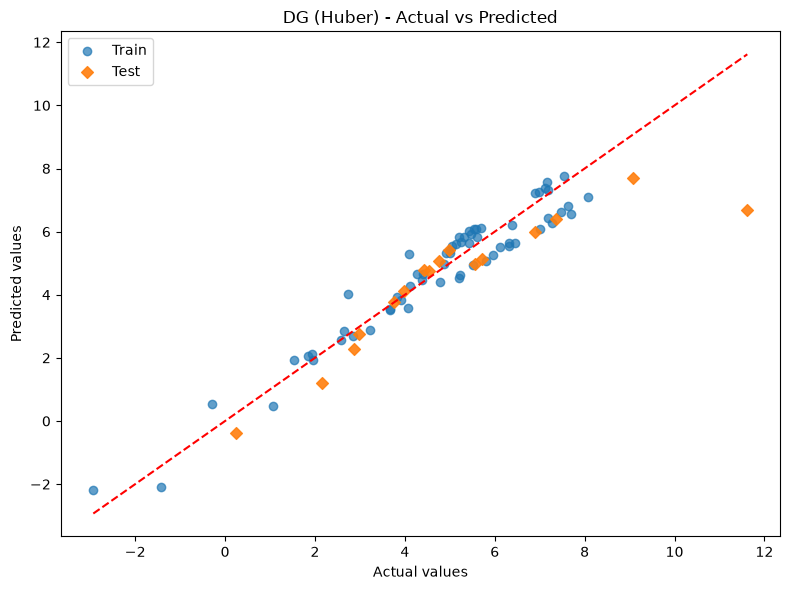


Best model for DG: Huber
Coefficients: [-0.70445894 -0.54584092 -0.92923477]
Intercept: 66.8751
Regression equation: y = 66.8751 + (-0.7045 * Cost of Revenue %) + (-0.5458 * Operating Expense %) + (-0.9292 * Interest Expense %)
------------------------------------------------------------
Ticker     Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  Test R²
  COST    RANSAC    0.136753   0.149919   0.108293  0.107697  0.919121 0.903516
  COST Theil-Sen    0.137268   0.151767   0.107264  0.108068  0.918510 0.901123
  COST     Huber    0.137174   0.157306   0.105777  0.110176  0.918622 0.893773
  COST  Quantile    0.136523   0.155021   0.105030  0.107802  0.919393 0.896838


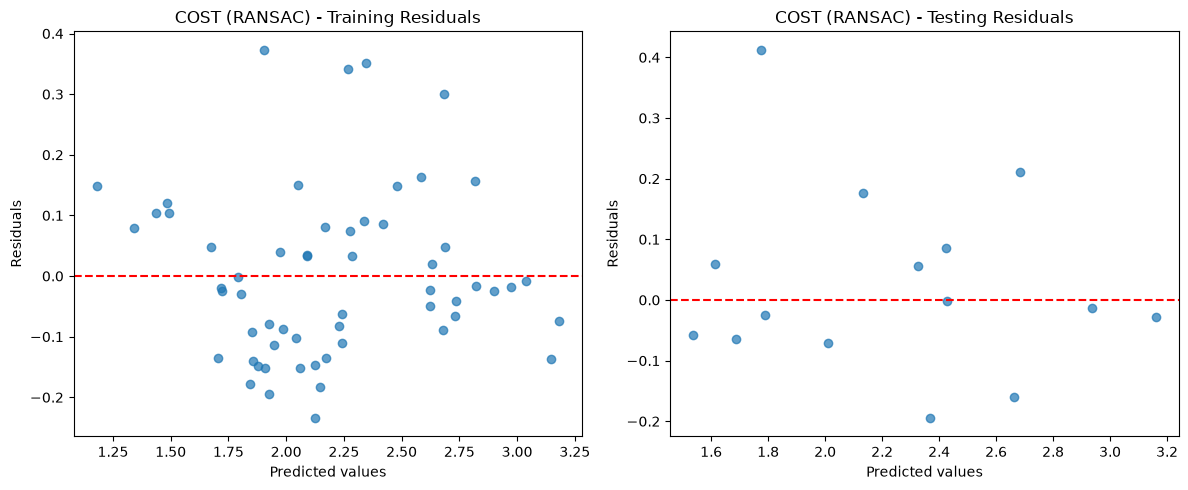

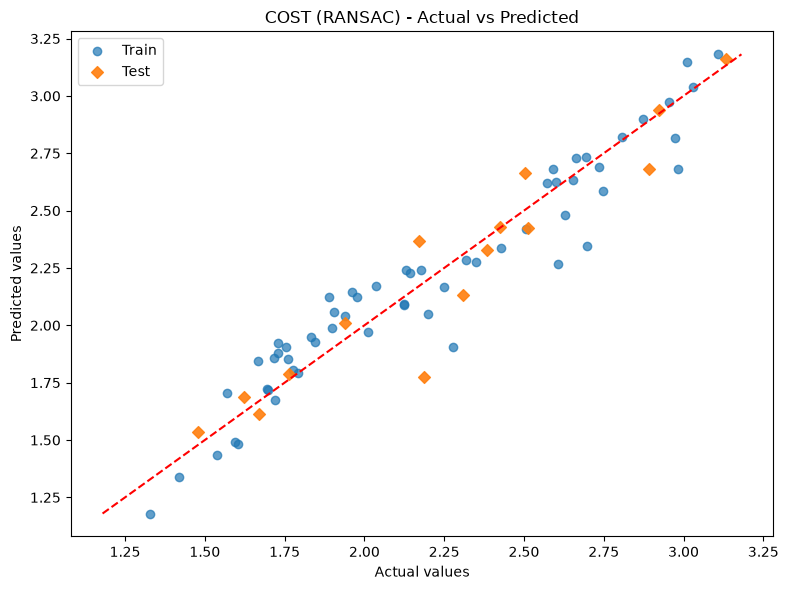


Best model for COST: RANSAC
Coefficients: [-0.89450268 -0.97261465 -2.86697389]
Intercept: 89.8774
Regression equation: y = 89.8774 + (-0.8945 * Cost of Revenue %) + (-0.9726 * Operating Expense %) + (-2.8670 * Interest Expense %)
------------------------------------------------------------


In [47]:
random_state = 42

for ticker in ml_data["Ticker"].unique():
    ticker_data = ml_data[ml_data["Ticker"] == ticker]
    X = pd.concat([ticker_data[feature_1.name], ticker_data[feature_2.name], ticker_data[feature_3.name]],   axis=1).to_numpy()
    y = ticker_data[target.name].to_numpy()

    # 1. Create a 1.5 * IQR outlier flag per ticker for stratified splitting
    q1, q3 = np.percentile(y, [25, 75])
    iqr = q3 - q1
    is_outlier = ((y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)).astype(int)

    # Stratify only if both normal and outlier classes have >= 2 rows (avoids ValueError on COST/TGT)
    _, class_counts = np.unique(is_outlier, return_counts=True)
    stratify_labels = is_outlier if (len(class_counts) > 1 and class_counts.min() >= 2) else None

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=random_state,
        stratify=stratify_labels,
    )

    # 2. Define models (alpha=0 prevents QuantileRegressor from collapsing to a flat line)
    models = {
        "RANSAC": RANSACRegressor(estimator=LinearRegression(), random_state=random_state),
        "Theil-Sen": Pipeline([
            ("scaler", StandardScaler()),
            ("regressor", TheilSenRegressor(random_state=random_state)),
        ]),
        "Huber": Pipeline([
            ("scaler", StandardScaler()),
            ("regressor", HuberRegressor()),
        ]),
        "Quantile": Pipeline([
            ("scaler", StandardScaler()),
            ("regressor", QuantileRegressor(alpha=0, solver="highs")),
        ]),
    }

    # 3. Fit, predict, and evaluate cleanly in one loop
    model_results = []
    fitted_artifacts = []

    for name, model in models.items():
        model.fit(X_train, y_train)
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
        test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
        train_mae = mean_absolute_error(y_train, y_train_pred)
        test_mae = mean_absolute_error(y_test, y_test_pred)

        model_results.append({
            "Ticker": ticker,
            "Model": name,
            "Train RMSE": train_rmse,
            "Test RMSE": test_rmse,
            "Train MAE": train_mae,
            "Test MAE": test_mae,
            "Train R²": model.score(X_train, y_train),
            "Test R²": model.score(X_test, y_test),
        })
        fitted_artifacts.append((name, model, test_mae, y_train_pred, y_test_pred))

    results_df = pd.DataFrame(model_results)
    print(results_df.to_string(index=False))

    # 4. Select the best model using Test MAE (not Train RMSE)
    best_name, best_model, _, best_train_pred, best_test_pred = min(
        fitted_artifacts, key=lambda item: item[2]
    )

    # 5. Draw residual plots for the winning model
    train_residuals = y_train - best_train_pred
    test_residuals = y_test - best_test_pred

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].scatter(best_train_pred, train_residuals, alpha=0.7)
    axes[0].axhline(0, color="red", linestyle="--")
    axes[0].set_title(f"{ticker} ({best_name}) - Training Residuals")
    axes[0].set_xlabel("Predicted values")
    axes[0].set_ylabel("Residuals")

    axes[1].scatter(best_test_pred, test_residuals, alpha=0.7)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_title(f"{ticker} ({best_name}) - Testing Residuals")
    axes[1].set_xlabel("Predicted values")
    axes[1].set_ylabel("Residuals")

    plt.tight_layout()
    plt.show()

    # 6. Visualize Actual vs Predicted (Train & Test) for the winning model
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(y_train, best_train_pred, alpha=0.7, label="Train")
    ax.scatter(y_test, best_test_pred, alpha=0.9, marker="D", label="Test")
    line_min = min(y.min(), best_train_pred.min(), best_test_pred.min())
    line_max = max(y.max(), best_train_pred.max(), best_test_pred.max())
    ax.plot([line_min, line_max], [line_min, line_max], color="red", linestyle="--")
    ax.set_title(f"{ticker} ({best_name}) - Actual vs Predicted")
    ax.set_xlabel("Actual values")
    ax.set_ylabel("Predicted values")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # 7. Unscale coefficients and intercept back to original feature units
    if isinstance(best_model, RANSACRegressor):
        fitted_regressor = best_model.estimator_
    elif isinstance(best_model, Pipeline):
        fitted_regressor = best_model.named_steps["regressor"]
    else:
        fitted_regressor = best_model

    coefficients = fitted_regressor.coef_.copy()
    intercept = float(fitted_regressor.intercept_)

    if isinstance(best_model, Pipeline):
        scaler = best_model.named_steps.get("scaler")
        if scaler is not None:
            coefficients = coefficients / scaler.scale_
            intercept = intercept - np.dot(coefficients, scaler.mean_)

    print(f"\nBest model for {ticker}: {best_name}")
    print(f"Coefficients: {coefficients}")
    print(f"Intercept: {intercept:.4f}")
    print(
        f"Regression equation: y = {intercept:.4f} + "
        + " + ".join(f"({coef:.4f} * {col})" for coef, col in zip(coefficients, [feature_1.name, feature_2.name, feature_3.name]))
    )
    print("-" * 60)


In [48]:
# View full net income percentage data for DLTR
print(ml_data.loc[ml_data["Ticker"] == "DLTR", "Net Income %"])

149     7.400106
150     7.292469
151     7.587450
152     8.661619
153     9.418652
         ...    
223     5.317279
224     2.735724
225     3.254191
226     4.122177
227    10.518891
Name: Net Income %, Length: 79, dtype: float64
